# Activity: Can We Trust the AI Analyst? — FreshKart Case

**Unit 4 · AI-Assisted Visualization · LLMs for EDA & Human-in-the-Loop Visualization**
Visualization of Data, Understanding and Interpretation (UE24CS342AA9)

---

## The case

**FreshKart** is a quick-commerce grocery chain with **10 dark stores in 3 cities** (Bengaluru, Pune, Hyderabad). Operations head **Meera** has a leadership meeting tomorrow. She asked an AI analytics assistant:

> *"Summarise our business from January to September and tell me what went wrong in September."*

The assistant has produced the report below. **You are the analyst.** Meera will present whatever you sign off, so your job is to **verify, correct or reject** each AI insight using the data, and to say *why*.

**Ground rules (from the lecture):** every number must come from code you can inspect · an alert tells you where to look, a chart tells you what is true · the AI proposes, the human decides.

**How to work:** run the notebook top to bottom. Complete every cell marked `# TODO` (replace `None` with your code or answer) and write in the cells marked **✏️ Your answer**. Cells that depend on your TODO will tell you if something is still missing.

### The data: `freshkart_orders.csv` (synthetic)

| Column | Meaning |
|---|---|
| `order_id` | unique order reference |
| `order_date` | date of order |
| `city`, `store_id` | where the order was fulfilled |
| `zone` | `Urban` or `Suburban` delivery address |
| `delivery_partner` | `Partner A` or `Partner B` |
| `items`, `discount_pct`, `order_value` | basket size, discount applied, bill value (₹) |
| `distance_km`, `delivery_minutes`, `on_time` | delivery distance, time taken, 1 if ≤ 30 min |
| `rating` | customer rating 1–5 (blank if not given) |
| `app_sessions_7d`, `loyalty_points` | customer app activity and loyalty balance |

In [2]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (6, 3.2), "axes.spines.top": False, "axes.spines.right": False})

def ready(*vals):
    """Helper: tells you if a TODO above is still unanswered."""
    ok = all(v is not None for v in vals)
    if not ok:
        print("⚠ Complete the TODO cell(s) above first, then re-run this cell.")
    return ok

df = pd.read_csv("freshkart_orders.csv", parse_dates=["order_date"])
df.head()

,order_id,order_date,city,store_id,zone,delivery_partner,items,discount_pct,order_value,distance_km,delivery_minutes,on_time,rating,app_sessions_7d,loyalty_points
0,FK100000,2026-01-01,Bengaluru,B1,Urban,Partner A,4,15,300,3.2,22,1,NaN,6,281
1,FK100001,2026-01-01,Bengaluru,B1,Urban,Partner A,3,5,187,1.8,16,1,4.0,4,299
2,FK100002,2026-01-01,Bengaluru,B1,Suburban,Partner A,2,20,244,2.7,28,1,3.0,8,387
3,FK100003,2026-01-01,Bengaluru,B1,Urban,Partner B,7,20,1223,1.4,20,1,4.0,8,234
4,FK100004,2026-01-01,Bengaluru,B1,Urban,Partner B,6,5,1156,3.5,28,1,5.0,11,226


## The AI assistant's report (to be validated)

| # | Insight type | AI statement |
|---|---|---|
| 1 | Trend | "Bengaluru orders grew steadily from January to September, by about **+56 orders per month**." |
| 2 | Distribution | "The **average order value is ₹465**." |
| 3 | Comparison | "Pune orders **more than doubled** from Q2 to Q3 (**+117%**), so the Pune expansion is a huge success." |
| 4 | Comparison | "Hyderabad orders **fell 28%** in September compared with August, **because delivery service there got worse**." |
| 5 | Comparison | "**Partner B is more punctual than Partner A** (93% vs 87% on time), so we should route all orders to Partner B." |
| 6 | Correlation | "Longer delivery times go with lower ratings (**r = −0.32** among rated orders)." |
| 7 | Correlation | "Bigger discounts and bigger baskets move together (**r = 0.38**)." |
| 8 | Comparison | "Suburban orders take about **5 minutes longer** to deliver than urban orders." |
| 9 | Prediction | "**Orders will recover in October.**" |

---
## Part 1 · Is the data trustworthy? Profile before you believe

An AI narrates a profile, so a flawed profile gives a confident but flawed story. Compute the basics yourself.

In [3]:
profile = {
    "rows": len(df),
    "columns": df.shape[1],
    "duplicate_rows": None,        # TODO: number of fully duplicated rows (hint: df.duplicated())
    "rating_missing_pct": None,    # TODO: % of rating values that are missing, 1 decimal
    "order_id_unique_pct": round(df["order_id"].nunique() / len(df) * 100, 1),
}
profile

{'rows': 13987,
 'columns': 15,
 'duplicate_rows': None,
 'rating_missing_pct': None,
 'order_id_unique_pct': 99.5}

mean = ₹465 | median = ₹358 | skew = 13.2


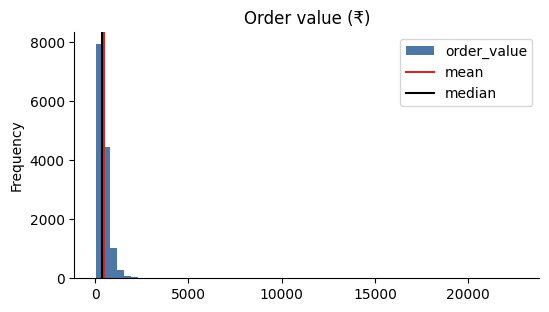

In [6]:
# From here on we work with the cleaned table (duplicates removed).
df = df.drop_duplicates().copy()

aov_mean = df["order_value"].mean()      # TODO: mean order_value
aov_median = df["order_value"].median()    # TODO: median order_value
aov_skew = round(stats.skew(df["order_value"]), 1)

if ready(aov_mean, aov_median):
    print(f"mean = ₹{aov_mean:.0f} | median = ₹{aov_median:.0f} | skew = {aov_skew}")
    df["order_value"].plot.hist(bins=60, color="#4c78a8", title="Order value (₹)")
    plt.axvline(aov_mean, color="#d62728", label="mean"); plt.axvline(aov_median, color="black", label="median")
    plt.legend(); plt.show()

In [7]:
# Where are the ratings missing?
df.groupby("city")["rating"].apply(lambda s: s.isna().mean() * 100).round(1)

,rating
city,
Bengaluru,21.1
Hyderabad,45.0
Pune,20.6


**✏️ Your answer (Part 1):**
(a) Which AI insight(s) are affected by what you just found about the *average*, and how should the statement be rewritten?
(b) Insight 6 uses ratings. What risk does the missing-rating pattern create?

*Your answer:*

(a) Insight 2 is affected because the mean order value of 465 rupees is considerably higher than the median of ₹358. The distribution is highly right-skewed, meaning a few unusually large orders increase the mean. The statement should report both measures instead of presenting the mean as representative of a typical order.

(b) Missing ratings create a risk of selection bias because customers who submit ratings may have different experiences from those who do not. This is particularly concerning because Hyderabad has 45% missing ratings, compared with approximately 21% in Bengaluru and Pune. Therefore, the correlation in Insight 6 may not represent all customers.


---
## Part 2 · Defaults shape the story: bin width

The assistant looked at a 1-minute-bin histogram of one store's deliveries and wrote: *"Delivery times are **multimodal**, with three separate peaks."* Look at the same 150 orders with different bin widths.

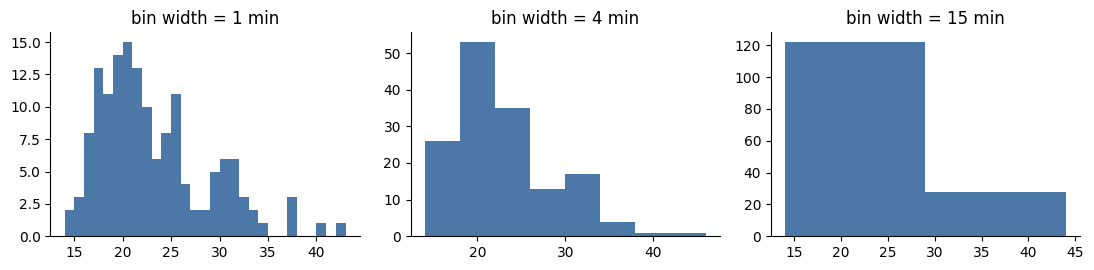

In [8]:
sample = df[df.store_id == "B3"].sample(150, random_state=1)["delivery_minutes"]
fig, axes = plt.subplots(1, 3, figsize=(11, 2.8))
for ax, w in zip(axes, [1, 4, 15]):
    ax.hist(sample, bins=np.arange(sample.min(), sample.max() + w, w), color="#4c78a8")
    ax.set_title(f"bin width = {w} min")
plt.tight_layout(); plt.show()

multimodal_supported = False    # TODO: True or False
best_bin_width = 4         # TODO: 1, 4 or 15

**✏️ Your answer (Part 2):** In one sentence, what should the analyst do before accepting a shape claim from an automated report?

*Your answer:*  The analyst should compare the distribution using multiple reasonable bin widths and verify whether the observed peaks remain consistent before accepting a shape claim from an automated report.

---
## Part 3 · Trends, correlations and patterns

### 3a · Trend (insight 1)

slope = 56.2 orders/month | Kendall tau = 0.89, p = 0.0002


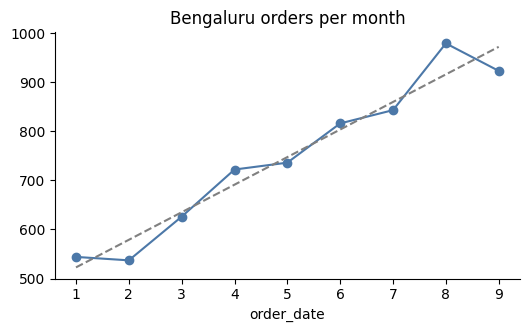

In [9]:
bengaluru = df[df.city == "Bengaluru"]
monthly = bengaluru.groupby(bengaluru["order_date"].dt.month).size()
months = monthly.index.values

slope = np.polyfit(months, monthly.values, 1)[0]   # TODO: slope of a straight-line fit of monthly orders on month (hint: np.polyfit(months, monthly.values, 1)[0])
tau, p_trend = stats.kendalltau(months, monthly.values)    # Mann–Kendall-style trend test

if ready(slope):
    print(f"slope = {slope:.1f} orders/month | Kendall tau = {tau:.2f}, p = {p_trend:.4f}")
    ax = monthly.plot(marker="o", color="#4c78a8", title="Bengaluru orders per month")
    ax.plot(months, np.polyval(np.polyfit(months, monthly.values, 1), months), "--", color="grey")
    plt.show()

### 3b · Correlation (insights 6 and 7)

discount~items r = 0.38 | minutes~rating r = -0.316 | hours~rating r = -0.316


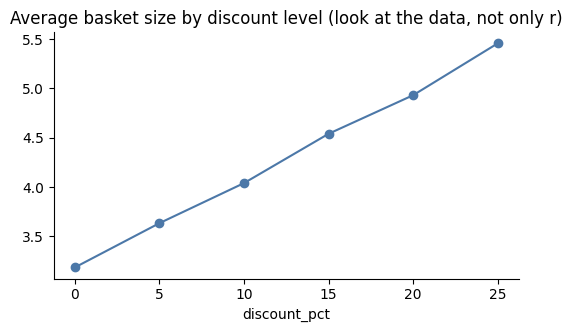

In [10]:
r_disc_items = df["discount_pct"].corr(df["items"])    # TODO: Pearson r between discount_pct and items

# Same question, different units: minutes -> hours
rated = df.dropna(subset=["rating"]).copy()
rated["delivery_hours"] = rated["delivery_minutes"] / 60
r_minutes = rated["delivery_minutes"].corr(rated["rating"])
r_hours = rated["delivery_hours"].corr(rated["rating"])
r_unchanged = np.isclose(r_minutes, r_hours)    # TODO: True/False - is r the same after rescaling? (hint: np.isclose)

if ready(r_disc_items, r_unchanged):
    print(f"discount~items r = {r_disc_items:.2f} | minutes~rating r = {r_minutes:.3f} | hours~rating r = {r_hours:.3f}")
    df.groupby("discount_pct")["items"].mean().plot(marker="o", color="#4c78a8",
        title="Average basket size by discount level (look at the data, not only r)")
    plt.show()

### 3c · Scanning many pairs

The assistant also scanned **every pair** of the 7 numeric columns below and flags any pair with p < 0.05 as a "finding".

In [11]:
num_cols = ["order_value", "items", "discount_pct", "distance_km", "delivery_minutes", "app_sessions_7d", "loyalty_points"]

n_pairs = len(num_cols) * (len(num_cols) - 1) // 2          # TODO: number of pairs from len(num_cols) variables
expected_false = n_pairs * 0.05   # TODO: expected false 'significant' pairs at alpha = 0.05 if nothing were real
bonferroni = 0.05 / n_pairs       # TODO: Bonferroni-corrected threshold

rows = []
for a, b in itertools.combinations(num_cols, 2):
    r, p = stats.pearsonr(df[a], df[b])
    rows.append((a, b, round(r, 3), p))
scan = pd.DataFrame(rows, columns=["x", "y", "r", "p"]).sort_values("p")

if ready(n_pairs, expected_false, bonferroni):
    print(f"pairs = {n_pairs} | expected false positives = {expected_false:.2f} | Bonferroni threshold = {bonferroni:.4f}")
    flagged = scan[scan["p"] < 0.05].copy()
    flagged["survives_bonferroni"] = flagged["p"] < bonferroni
    display(flagged)

pairs = 21 | expected false positives = 1.05 | Bonferroni threshold = 0.0024


,x,y,r,p,survives_bonferroni
0,order_value,items,0.325,0.000000e+00,True
6,items,discount_pct,0.378,0.000000e+00,True
15,distance_km,delivery_minutes,0.748,0.000000e+00,True
1,order_value,discount_pct,0.066,5.802888e-15,True
14,discount_pct,loyalty_points,-0.022,8.317915e-03,False


**✏️ Your answer (3a–3c):**
(a) Insight 1 rests on 9 monthly points. Is the trend claim reasonable, and what would you show with it?
(b) Insight 7 says discounts and baskets "move together". Does the chart support the wording, and can the AI say discounts *cause* bigger baskets?
(c) Look at the flagged table. Which pair is most likely a false alarm, and what are **two** reasons you say so?

*Your answer:*

(a) The Bengaluru trend is reasonable because the monthly order counts show an overall upward pattern, with a slope of approximately 56 additional orders per month. However, there is a small decline in February, so describing the growth as completely steady would be misleading. I would present the monthly order counts with the trend line and the Kendall test result.

(b) The chart supports a positive relationship between discounts and basket size. The correlation is approximately 0.38, and average basket size increases across discount levels. However, correlation does not establish causation, so the AI cannot conclude that discounts directly cause customers to purchase more items.

(c) The discount percentage and loyalty points pair is the most likely false alarm. Its correlation is extremely weak (approximately -0.022), and its p-value does not survive the Bonferroni correction. Also, testing 21 pairs increases the probability of obtaining statistically significant results by chance.

### 3d · Patterns: grouping the stores

The assistant ran **PCA + k-means (k = 3)** on store-level features and proposed three store "segments".

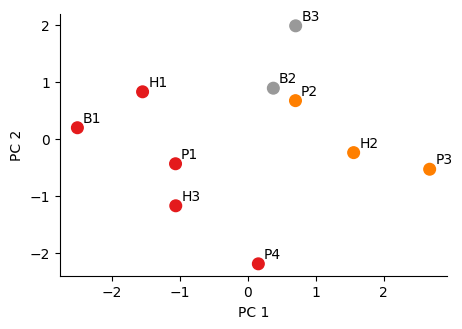

,segment,orders_per_active_day,on_time,suburban_share
store_id,,,,
B1,0,8.29,0.92,0.35
H1,0,4.99,0.91,0.35
P1,0,4.76,0.90,0.37
H3,0,4.30,0.91,0.39
P4,0,4.34,0.88,0.41
H2,1,5.24,0.89,0.45
P3,1,5.25,0.88,0.48
P2,1,4.39,0.91,0.42
B2,2,8.90,0.90,0.45


In [12]:
d = df.assign(month=df["order_date"].dt.month)
store = df.groupby("store_id").agg(
    orders=("order_id", "count"),
    median_value=("order_value", "median"),
    on_time=("on_time", "mean"),
    suburban_share=("zone", lambda s: (s == "Suburban").mean()),
    avg_discount=("discount_pct", "mean"),
    active_days=("order_date", "nunique"),
)
store["orders_per_active_day"] = store["orders"] / store["active_days"]
feats = store.drop(columns=["orders", "active_days"])

Z = StandardScaler().fit_transform(feats)
pcs = PCA(n_components=2).fit_transform(Z)
store["segment"] = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(Z)

fig, ax = plt.subplots(figsize=(5, 3.4))
ax.scatter(pcs[:, 0], pcs[:, 1], c=store["segment"], cmap="Set1", s=70)
for sid, (x, y) in zip(store.index, pcs):
    ax.annotate(sid, (x, y), xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); plt.show()
store[["segment", "orders_per_active_day", "on_time", "suburban_share"]].round(2).sort_values("segment")

**✏️ Your answer (3d):** The AI says these are three meaningful store "types". With only 10 stores, what is one reason a human should hesitate, and what would you check before naming the segments?

*Your answer:* With only 10 stores, clustering can produce unstable segments because even a small change in the data can significantly affect the grouping. Before naming the segments, I would examine the actual characteristics of each store, check whether the groups are meaningfully different and test whether the results remain consistent with different clustering settings.

---
## Part 4 · From an observation to hypotheses (insight 4)

**Observation:** Hyderabad orders fell sharply in September. The AI jumped straight to "service got worse". A better assistant would list *competing* hypotheses and the evidence that separates them:

| | Hypothesis | Test |
|---|---|---|
| A | Delivery service got worse | on-time % in Aug vs Sep |
| B | A data problem: some store has missing rows | rows per store per week |
| C | Discounts were cut in September | mean discount, Aug vs Sep |
| D | Customers switched to a competitor | needs competitor/customer data we do not have |

In [13]:
hyd = df[df.city == "Hyderabad"]
hyd_month = hyd.groupby(hyd["order_date"].dt.month).size()

change_pct = (
    (hyd_month.loc[9] - hyd_month.loc[8]) / hyd_month.loc[8]
) * 100

     # TODO: % change in Hyderabad orders from August (month 8) to September (month 9)
first_test = "B"     # TODO: which hypothesis is the cheapest to rule out first? 'A', 'B', 'C' or 'D'

if ready(change_pct, first_test):
    print(f"Hyderabad Aug -> Sep: {change_pct:.1f}% | cheapest test first: {first_test}")

Hyderabad Aug -> Sep: -28.4% | cheapest test first: B


In [14]:
# Run the tests for hypotheses B and A
weekly = hyd.groupby([pd.Grouper(key="order_date", freq="W"), "store_id"]).size().unstack(fill_value=0)
display(weekly.tail(9))

ontime = hyd.groupby(hyd["order_date"].dt.month)["on_time"].mean() * 100
ontime_change_pts = ontime.loc[9] - ontime.loc[8]   # TODO: on-time % in September minus on-time % in August
culprit_store = weekly.eq(0).sum().idxmax()       # TODO: which store ('H1', 'H2' or 'H3') has a gap in its weekly rows?

if ready(ontime_change_pts, culprit_store):
    print(f"on-time change Aug->Sep = {ontime_change_pts:+.1f} points | store with the gap: {culprit_store}")

store_id,H1,H2,H3
order_date,,,
2026-08-09,33,36,39
2026-08-16,41,32,17
2026-08-23,39,35,36
2026-08-30,46,39,28
2026-09-06,37,28,36
2026-09-13,33,0,21
2026-09-20,43,0,38
2026-09-27,38,11,31
2026-10-04,17,18,19


on-time change Aug->Sep = -0.3 points | store with the gap: H2


**✏️ Your answer (Part 4):** In two sentences, which hypotheses did the data support or rule out? Write the corrected version of insight 4 that you would be willing to show Meera.

*Your answer:* The data supports Hypothesis B because H2 has zero recorded orders in two September weeks, suggesting a possible data gap. Hypothesis A is not supported because on-time delivery performance decreased by only 0.3 percentage points, while discounts were not reduced, and Hypothesis D cannot be tested with the available data.

Hyderabad orders decreased by approximately 28.4% in September compared with August. Missing weekly records at H2 may explain part of this decline, so the data should be investigated before attributing the reduction to delivery service.

---
## Part 5 · Validate and correct two more claims

### 5a · "Pune orders more than doubled" (insight 3)

In [15]:
pune = df[df.city == "Pune"].copy()
pune["quarter"] = pune["order_date"].dt.quarter
by_store = pune.pivot_table(index="store_id", columns="quarter", values="order_id", aggfunc="count", fill_value=0)
display(by_store)

old = by_store.loc[["P1", "P2"]]                  # the stores that were open in both Q2 and Q3
like_for_like_pct = (
    (old[3].sum() - old[2].sum()) / old[2].sum()
) * 100   # TODO: % change in Q3 vs Q2 orders for these two stores (columns 2 and 3)

if ready(like_for_like_pct):
    print(f"like-for-like growth = {like_for_like_pct:+.1f}%")

quarter,1,2,3
store_id,,,
P1,423,423,443
P2,388,380,421
P3,0,0,483
P4,0,0,399


like-for-like growth = +7.6%


Now draw the *corrected* message. The chart below already greys the context and highlights the new stores (Knaflic: grey the context, one accent colour, title with the takeaway). **Write the title.**

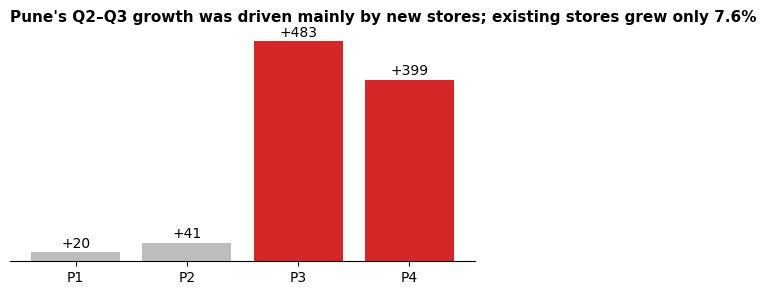

In [16]:
title = "Pune's Q2–Q3 growth was driven mainly by new stores; existing stores grew only 7.6%"    # TODO: a one-sentence, takeaway title (state the finding, not just "Orders by store")

change = by_store[3] - by_store[2]
colors = ["#bdbdbd" if s in ("P1", "P2") else "#d62728" for s in by_store.index]
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(change.index, change.values, color=colors)
for x, v in zip(change.index, change.values):
    ax.text(x, v + 10, f"{v:+d}", ha="center")
ax.set_yticks([]); ax.spines["left"].set_visible(False)
ax.set_title(title if title else "(write a takeaway title)", loc="left", fontsize=11, fontweight="bold")
plt.show()

### 5b · "Partner B is more punctual, send everything to B" (insight 5)

In [17]:
overall = df.groupby("delivery_partner")["on_time"].mean().mul(100).round(1)
mix = (pd.crosstab(df["delivery_partner"], df["zone"], normalize="index") * 100).round(0)
print("Overall on-time %:\n", overall, "\n\nShare of each partner's orders by zone (%):\n", mix)

by_zone = (
    df.groupby(["zone", "delivery_partner"])["on_time"]
    .mean()
    .mul(100)
    .unstack()
)   # TODO: on-time % for every (zone, partner) combination, as a table (groupby two keys, then .unstack())
better_in_every_zone = "Partner A"   # TODO: 'Partner A' or 'Partner B' - who is better inside each zone?
phenomenon = "Simpson's paradox"             # TODO: name the effect (two words)

if ready(by_zone, better_in_every_zone, phenomenon):
    display(by_zone)
    print(f"Better inside every zone: {better_in_every_zone} | effect: {phenomenon}")

Overall on-time %:
 delivery_partner
Partner A    87.1
Partner B    93.0
Name: on_time, dtype: float64 

Share of each partner's orders by zone (%):
 zone              Suburban  Urban
delivery_partner                 
Partner A             67.0   33.0
Partner B             16.0   84.0


delivery_partner,Partner A,Partner B
zone,,
Suburban,81.407821,72.031662
Urban,98.800185,96.920821


Better inside every zone: Partner A | effect: Simpson's paradox


**✏️ Your answer (Part 5):** (a) Rewrite insight 3 so it is honest. (b) Explain in plain language why Partner B *looks* better overall, and what question a careful human asks before accepting a comparison like insight 5.

*Your answer:*

(a) Pune's total orders increased by approximately 117% from Q2 to Q3, but this growth was largely influenced by the opening of new stores P3 and P4. The existing stores P1 and P2 experienced only 7.6% like-for-like growth, so the expansion should not be described as entirely organic growth.

(b) Partner B appears more punctual overall because it handles a much larger proportion of urban deliveries, which are generally easier to complete on time. Partner A handles more suburban deliveries, which take longer. A careful analyst should ask whether the partner still performs better when comparing deliveries within the same zone. This is an example of Simpson's paradox because the overall comparison reverses the within-zone comparison.

---
## Part 6 · Triage the whole report

For each AI insight decide: **Accept** (correct as stated), **Correct** (the finding is useful but the wording or number must change) or **Reject** (not supported). Then measure the AI.

In [19]:
decisions = {
    1: "Correct",   # Bengaluru trend
    2: "Correct",   # average order value
    3: "Correct",   # Pune doubled
    4: "Correct",   # Hyderabad fell because service worsened
    5: "Correct",   # Partner B more punctual
    6: "Accept",   # delivery time vs rating
    7: "Accept",   # discount vs basket
    8: "Accept",   # suburban slower (check it yourself: df.groupby("zone")["delivery_minutes"].mean())
    9: "Reject",   # recovery prediction
}
analysts_true_insights = 7    # true insights an expert team found in this data (given)

accepted = 3     # TODO: how many insights did you mark 'Accept'?
if all(v in ("Accept", "Correct", "Reject") for v in decisions.values()):
    accepted = sum(v == "Accept" for v in decisions.values())
    precision = accepted / len(decisions)
    recall = accepted / analysts_true_insights
    f1 = 2 * precision * recall / (precision + recall) if accepted else 0
    print(f"Accepted as stated: {accepted}/{len(decisions)} | precision = {precision:.2f} | recall = {recall:.2f} | F1 = {f1:.2f}")
    print(f"Review effort spent on insights that were not fully correct: {(len(decisions) - accepted) / len(decisions):.0%}")
else:
    print("⚠ Fill in all nine decisions with 'Accept', 'Correct' or 'Reject'.")

Accepted as stated: 3/9 | precision = 0.33 | recall = 0.43 | F1 = 0.38
Review effort spent on insights that were not fully correct: 67%


**✏️ Your answer (Part 6):** Using precision and recall, would you describe this AI as an *assistant* or a *replacement* for the analyst? Justify in two sentences.

*Your answer:*  I would describe this AI as an assistant rather than a replacement for the analyst. Its precision and recall show that not all insights can be accepted without verification, and several conclusions require corrections or additional investigation. Human analysts must validate the findings before using them for business decisions.

---
## Part 7 · Communicating, steering and validating

### 7a · Three kinds of reading
Each insight reads the data at a different level: **`data`** (restates what is plotted), **`between`** (relationships or patterns) or **`beyond`** (predictions and causal explanations; the risk zone).

In [20]:
levels = {
    2: "data",   # "The average order value is ₹465."
    6: "between",   # "Longer delivery times go with lower ratings."
    9: "beyond",   # "Orders will recover in October."
}      # TODO: use 'data', 'between' or 'beyond'
print(levels)

{2: 'data', 6: 'between', 9: 'beyond'}


### 7b · Steering the assistant (interactive refinement)
Match each thing Meera types to the kind of feedback it is: **Reject**, **Constrain**, **Steer**, **Adjust** or **Pin**.

In [21]:
user_actions = {
    '"Never use pie charts in this report"': "Constrain",
    '"Use 5-minute bins for delivery time"': "Adjust",
    '"Focus on on-time rate by city"': "Steer",
    '"Keep the like-for-like Pune chart on the dashboard"': "Pin",
    '"Not this chart again"': "Reject",
}   # TODO: replace None with one of 'Reject', 'Constrain', 'Steer', 'Adjust', 'Pin'
user_actions

{'"Never use pie charts in this report"': 'Constrain',
 '"Use 5-minute bins for delivery time"': 'Adjust',
 '"Focus on on-time rate by city"': 'Steer',
 '"Keep the like-for-like Pune chart on the dashboard"': 'Pin',
 '"Not this chart again"': 'Reject'}

### 7c · Which validation threat?
Meera now says: *"My real worry is why **repeat customers** are leaving. The AI answered a different question: how orders changed."* The AI's numbers were all computed correctly.

In [22]:
threat = "wrong problem"   # TODO: 'wrong problem', 'wrong abstraction', 'wrong idiom' or 'wrong algorithm' (Munzner)
threat

'wrong problem'

**✏️ Your answer (Part 7):** Rewrite insight 2 *and* insight 4 as statements you would be comfortable presenting. Each rewrite should use the right measure or the right scope, avoid causal language the data cannot support, and be specific (no "interesting variation").

*Your answer:*

Insight 2 – Corrected statement:

"The average order value is approximately ₹465, while the median order value is ₹358. The distribution is highly right-skewed, indicating that unusually large orders increase the mean, so the median provides a better representation of a typical order."

Insight 4 – Corrected statement:

"Hyderabad recorded 346 orders in September compared with 483 in August, representing a 28.4% decrease. H2 had no recorded orders in two September weeks, while the overall on-time delivery rate decreased by only 0.3 percentage points. The missing records should be investigated before attributing the decline to delivery performance."

---
## Reflection

Answer in 2–4 sentences each. There are no right-or-wrong answers here; we are looking for honest thinking about *your own* process.

**1. Automation bias.** Before you checked anything, which AI insight did you find most convincing? What made it convincing (the number, the tone, the chart, the confident wording), and would you have caught the problem without the checks?

*Your reflection:* The insight that Pune orders more than doubled initially seemed convincing because it included a specific percentage and confidently described the expansion as a success. However, after checking the existing stores separately, I realised that most of the growth came from newly opened stores rather than significant growth in existing stores. Without these checks, I might have accepted the AI's conclusion without questioning it.

**2. Choosing the level of automation.** For FreshKart, name one task where you would let the AI work with little supervision and one where you would insist on a human check. What did you use to decide (stakes, reversibility, how visible errors are)?

*Your reflection:* I would allow AI to automate repetitive tasks such as calculating averages, identifying missing values and generating preliminary charts because these tasks are relatively easy to verify. However, I would insist on human supervision when interpreting business trends or making operational decisions because incorrect conclusions could have significant consequences.

**3. Making trust cheaper.** Pick one problem you found (e.g. the Hyderabad gap, the missing ratings, or Partner B). What should the AI tool have *shown* (code, sample size, data gaps, uncertainty) so you could verify it faster, and what control would you want (edit, undo, switch off)?

*Your reflection:* For the Hyderabad order decline, the AI should have displayed weekly order counts for each store, highlighted missing records and shown the August-to-September comparison. This would have made it easier to identify the H2 data gap without manually investigating the entire dataset. I would also want the ability to inspect, edit and undo the AI's conclusions before including them in a report.

**4. Responsibility.** If Meera presents the corrected report and one number is still wrong, who is accountable, the AI, the tool's vendor, you or Meera? What would you do differently next time to carry that responsibility well?

*Your reflection:* The human analyst who verifies and approves the report, along with Meera as the person presenting it, must take responsibility for ensuring that the information is accurate. The AI and its vendor also have responsibilities regarding the reliability and transparency of the system, but they cannot replace human accountability. Next time, I would independently verify important findings, document the validation process and retain the underlying calculations before approving the report.